<h1>Transformer Text Generator</h1>

<h2>1. Business understanding</h2>

The goal of this project is to build a text generator using a Transformer model. The model will be trained on Sherlock Holmes text from Project Gutenberg.

The aim is to understand how a Transformer learns from text and how different model settings affect the quality of generated text.

<h2>2. Data understanding</h2>

The dataset consists of the book `The case-book of Sherlock Holmes by Arthur Conan Doyle`, which was downloaded from [Project Gutenberg](https://www.gutenberg.org/). The dataset contains English language stories about Sherlock Holmes and provides the material for training the text generation model.
  - Book name: The Case-Book of Sherlock Holmes
  - Author: Arthur Conan Doyle
  - Language: English
  - Source: Project Gutenberg
  - Original data size: 462.19 KB
  - Original text lenght: 473,158 characters
  - Cleaned data size: 443.14 KB
  - Cleaned text lenght: 453,762 characters

The book was chosen because it has more than 100 KB clean text and it contains interesting language patterns for a transformer model to learn. And most importantly, the material could be used freely.

In [1]:
import os

import numpy as np
import keras
import sentencepiece as spm
import matplotlib.pyplot as plt
import time #for measuring model training time

# set a random seed for reproducibility (results are reproducible when the whole notebook 
# is run from top to bottom)
seed = 54
keras.utils.set_random_seed(seed)

print(f"Keras version: {keras.__version__}")
print(f"Keras backend: {keras.config.backend()}")

Keras version: 3.15.1
Keras backend: tensorflow


We start by loading the data and checking it's size.

In [2]:
file_path = "./txt/The_Project_Gutenberg.txt"
size_bytes = os.path.getsize(file_path)

with open(file_path, 'r', encoding='utf-8-sig') as file: # load the project gutenberg text
    text = file.read()

print(f"Text length: {len(text)} characters")
print(f'File size: {round(size_bytes / 1024, 2)} KB')
print(f"First 100 characters: {text[:100]}")

Text length: 473158 characters
File size: 462.19 KB
First 100 characters: The Project Gutenberg eBook of The case-book of Sherlock Holmes
    
This eBook is for the use of an


After loading the data, we see that the dataset length consist of `473,158 characters`. Note that this contains the license texts before and after the actual e-book. The file size is `462.19 KB`. The first 100 characters show the beginning of the book.

<h2>3. Data preparation</h2>

The code trains a SentencePiece tokenizer using the Gutenberg text dataset with the Byte Pair Encoding algorithm. The goal is to create a BPE based tokenizer trained on Gutenberg text that splits text into smaller, reusable token units. Each token is assigned a numerical ID. These IDs are used as input to the Transformer model.

License text from the beginning and end is removed. The original full text is saved into `text` variable, and the clean text without license text into `clean_text`. The `clean_text` contains 453,762 characters.

In [3]:
# remove license text from the beginning and end
start = text.find("*** START OF")
start = text.find("\n", start) + 1
end = text.find("*** END OF")
clean_text = text[start:end]
clean_size_bytes = len(clean_text.encode("utf-8"))
print("Original text lenght:", len(text), "\nLength after license texts removed:", len(clean_text))
print(f"Clean text size: {clean_size_bytes / 1024:.2f} KB")

Original text lenght: 473158 
Length after license texts removed: 453762
Clean text size: 443.14 KB


Next we prepare the tokenized Gutenberg text for training a language model.

### Clean tokenizer without the license text
The tokenizer uses the `clean_text`, which does not have the license text. The trained SentencePiece tokenizer is saved into `sp_clean`, which uses prefix `gutenberg_sp_clean`. 

In [4]:
# train SentencePiece model on the cleaned text (license text removed)
# save clean text to a temporary file for SentencePiece training

temp_file_clean = 'gutenberg_temp_clean.txt'
with open(temp_file_clean, 'w', encoding='utf-8') as f:
    f.write(clean_text)

# train SentencePiece model
vocab_size = 2000
model_prefix_clean = 'gutenberg_sp_clean'  # separate prefix so the first tokenizer is not overwritten

spm.SentencePieceTrainer.train(
    input=temp_file_clean,
    model_prefix=model_prefix_clean,
    vocab_size=vocab_size,
    character_coverage=1.0,
    model_type='bpe',
    user_defined_symbols=['<PAD>', '<UNK>']
)

# load the trained tokenizer
sp_clean = spm.SentencePieceProcessor()
sp_clean.load(f"{model_prefix_clean}.model")

# test tokenization
test_text = "It was from the Carlton Club"
tokens = sp_clean.encode_as_pieces(test_text)

print(f"Tokenized example: {tokens}")
print(f"Vocabulary size: {sp_clean.get_piece_size()}")

Tokenized example: ['▁It', '▁was', '▁from', '▁the', '▁C', 'ar', 'lt', 'on', '▁C', 'l', 'ub']
Vocabulary size: 2000


The trained tokenizer is loaded and tested by tokenizing the sentence "It was from the Carlton Club". The code prints the resulting tokens and the actual vocabulary size.

Next we prepare the tokenized clean text for training a language model.

In [5]:
# prepare training data from the cleaned text

seq_length = 64
pieces_clean = sp_clean.encode_as_ids(clean_text)
print(f"Total tokens: {len(pieces_clean)}")

sequences_clean = []
for i in range(0, len(pieces_clean) - seq_length):
    sequences_clean.append(pieces_clean[i:i+seq_length+1])

sequences_clean = np.array(sequences_clean)
inputs_clean = sequences_clean[:, :-1]
targets_clean = sequences_clean[:, 1:]

print(f"Number of sequences: {len(sequences_clean)}")
print(f"Input shape: {inputs_clean.shape}")
print(f"Target shape: {targets_clean.shape}")

# 90 % train / 10 % validation, skipping seq_length sequences at the boundary
split_clean = int(0.9 * len(sequences_clean))
train_inputs_clean = inputs_clean[:split_clean]
train_targets_clean = targets_clean[:split_clean]
val_inputs_clean = inputs_clean[split_clean + seq_length:]
val_targets_clean = targets_clean[split_clean + seq_length:]

Total tokens: 132112
Number of sequences: 132048
Input shape: (132048, 64)
Target shape: (132048, 64)


The output displays the informaton about our training data. We can see, that the total amount of tokens created is `132112`.

<h2>4. Modeling</h2>

Now we train 4 different models, and inspect how different parameters affect each models training time and quality.

Every model uses `EarlyStopping`, where `patience is 3`.

### Model 1

Here we start by building a small Transformer-based language model that learns to predict the next token in a sequence. The model is stored as `model_clean`.

In [6]:
# define the models, done once
def get_positional_encoding(max_len, d_model):
    """Create sinusoidal positional encoding."""
    positions = np.arange(max_len)[:, np.newaxis]
    angles = np.arange(d_model)[np.newaxis, :] / d_model
    angles = 1 / (10000**angles)

    pos_encoding = positions * angles
    pos_encoding[:, 0::2] = np.sin(pos_encoding[:, 0::2])
    pos_encoding[:, 1::2] = np.cos(pos_encoding[:, 1::2])

    return pos_encoding

In [7]:
# define model parameters
embed_dim = 64
num_heads = 2
ff_dim = 128
num_layers = 2

# create the model
inputs_clean_layer = keras.Input(shape=(seq_length,))
embedding_layer = keras.layers.Embedding(sp_clean.get_piece_size(), embed_dim)(inputs_clean_layer)

# add positional encoding
pos_encoding = get_positional_encoding(seq_length, embed_dim)
x = embedding_layer + pos_encoding

# transformer blocks
for _ in range(num_layers):
    attention_output = keras.layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=embed_dim // num_heads,
        dropout=0.1
    )(x, x, use_causal_mask=True)
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + attention_output)

    ffn = keras.Sequential([
        keras.layers.Dense(ff_dim, activation="relu"),
        keras.layers.Dense(embed_dim),
        keras.layers.Dropout(0.1)
    ])
    ffn_output = ffn(x)
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + ffn_output)

# final output layer
outputs_clean = keras.layers.Dense(sp_clean.get_piece_size())(x)

model_clean = keras.Model(inputs=inputs_clean_layer, outputs=outputs_clean)

model_clean.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

model_clean.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 64)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 64, 64)    │    128,000 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 64, 64)    │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 64)    │     16,640 │ add[0][0],        │
│ (MultiHeadAttentio… │                   │            │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 64, 64)    │          0 │ add[0][0],        │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 64, 64)    │        128 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 64, 64)    │     16,576 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 64, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ sequential[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 64)    │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 64, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_3[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_1        │ (None, 64, 64)    │     16,576 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 64, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ sequential_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_4[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 64, 2000)  │    130,000 │ layer_normalizat… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 324,944 (1.24 MB)

 Trainable params: 324,944 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

After the models parameters are defined, we move on training the model. The history is saved as `history_01`.

In [8]:
batch_size = 32
epochs = 30

start_time = time.perf_counter()

history_01 = model_clean.fit(
    train_inputs_clean, train_targets_clean,
    validation_data=(val_inputs_clean, val_targets_clean),
    batch_size=batch_size,
    epochs=epochs,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=1),
        keras.callbacks.ModelCheckpoint('gutenberg_best_model_clean.keras', save_best_only=True)
    ]
)

training_time = time.perf_counter() - start_time

print(f"Training time: {training_time:.2f} seconds")

Epoch 1/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 313s 81ms/step - accuracy: 0.1497 - loss: 4.8210 - val_accuracy: 0.1629 - val_loss: 4.6310 - learning_rate: 3.0000e-04
Epoch 2/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 288s 77ms/step - accuracy: 0.2235 - loss: 3.8000 - val_accuracy: 0.1792 - val_loss: 4.6600 - learning_rate: 3.0000e-04
Epoch 3/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 287s 77ms/step - accuracy: 0.2577 - loss: 3.4870 - val_accuracy: 0.1833 - val_loss: 4.7382 - learning_rate: 1.5000e-04
Epoch 4/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 288s 77ms/step - accuracy: 0.2734 - loss: 3.3623 - val_accuracy: 0.1829 - val_loss: 4.7888 - learning_rate: 7.5000e-05
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 1.
Training time: 1175.34 seconds


`EarlyStopping` measures `val_loss` as default and saves the best model based on the best `val_loss` value.

We continue by plotting the training metrics and save the model as `gutenberg_model_clean.keras`.

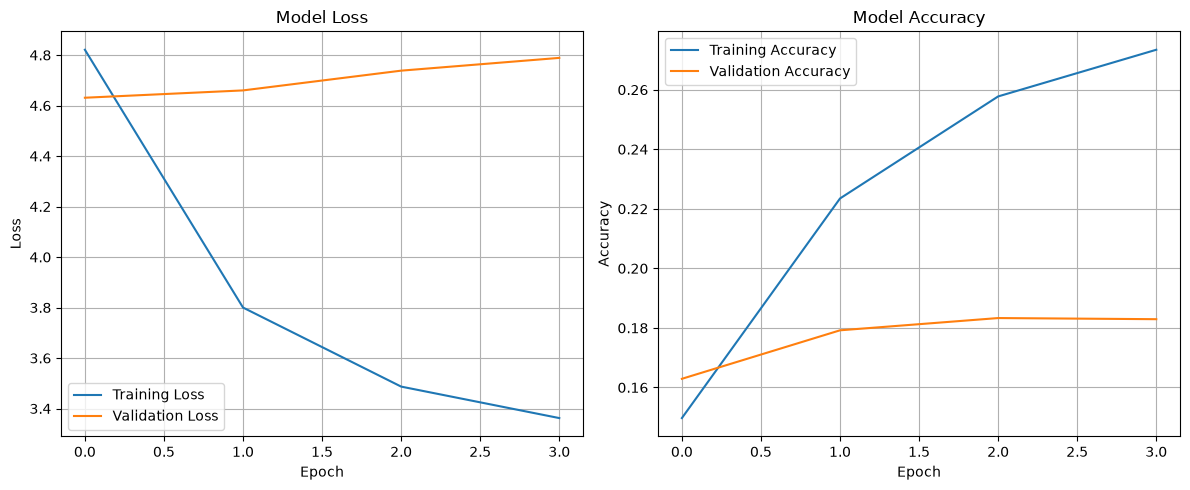

In [9]:
# function to plot training metrics, used by the models
def plot_training_metrics(history):
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.grid()
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.grid()
    plt.legend()

    plt.tight_layout()
    plt.show()
    
plot_training_metrics(history_01)

# save the model
model_clean.save('gutenberg_model_clean_B.keras')

Now, let's generate text with the sample text (`prompt`). We use the number of tokens (100) and temperature (1.2).

In [10]:
def generate_text(model, sp, prompt, num_tokens=100, temperature=1.0): # generated once for all the models
    """
    Generate text autoregressively.

    Args:
        temperature: Controls randomness
            - Low (0.1-0.5): Focused, repetitive
            - Medium (0.7-1.0): Balanced
            - High (1.5+): Creative, chaotic
    """
    # Encode the prompt
    input_ids = sp.encode_as_ids(prompt)

    # Rest of your generation code stays the same...
    if len(input_ids) < seq_length:
        padding_length = seq_length - len(input_ids)
        input_ids = [0] * padding_length + input_ids
    else:
        padding_length = 0
        input_ids = input_ids[-seq_length:]

    # Generated tokens
    generated_ids = list(input_ids[padding_length:])

    # Generate text token by token
    for _ in range(num_tokens):
        x = np.array([input_ids])
        predictions = model.predict(x, verbose=0)[0]
        logits = predictions[-1]
        logits = logits / temperature
        exp_logits = np.exp(logits - np.max(logits))
        probs = exp_logits / np.sum(exp_logits)
        next_token = np.random.choice(len(probs), p=probs)
        generated_ids.append(next_token)
        input_ids = input_ids[1:] + [next_token]

    # Decode the generated sequence
    generated_text = sp.decode(generated_ids)

    return generated_text

In [11]:
# generate sample text (other models use "prompts" as well)
prompts = [
    "It was from the Carlton Club",
    "Have you ever heard of Baron Gruner?",
    "Then you will sympathize with the client",
    "Our visitor was greatly disturbed"
]

for prompt in prompts:
    print(f"\nPrompt: {prompt}")
    generated = generate_text(model_clean, sp_clean, prompt, num_tokens=100, temperature=1.2)
    print(generated)


Prompt: It was from the Carlton Club
It was from the Carlton Clubxt upon the world miars while our caction of heart like importantle col'ticat and never heard." "Becut! The bit further Sere us or my plet and circag miss, and speak of resings, or the detek full stone. Wasinoolcon to fear. This denot away in some scoured being musence with the suck a viction'tos each side of his adver

Prompt: Have you ever heard of Baron Gruner?
Have you ever heard of Baron Gruner? What, there you might track.' Gibson, that he again before I speak so how sooner am. I could, we imposs to sight possibleiows, rusion of those sp when I was a wild to do when sal. His fatherative had out asy intellted that when she lipped those hadfully emergedech in the detemernourance. "Thickween sucatenses Gibson. Down very exual that he

Prompt: Then you will sympathize with the client
Then you will sympathize with the client spished fiances." "Yes, you interest at least possible terri reermace, if it is seen me. Murdoch

Let's print the training results from the best epoch.

In [12]:
# get the best epoch
best_epoch = int(np.argmin(history_01.history['val_loss']))
print(f"Best epoch: {best_epoch + 1}")

# print results
for key in ['loss', 'accuracy', 'val_loss', 'val_accuracy']:
    print(f"{key}: {history_01.history[key][best_epoch]:.4f}")

Best epoch: 1
loss: 4.8210
accuracy: 0.1497
val_loss: 4.6310
val_accuracy: 0.1629


The model is clearly overfitted. It has high value loss and low accuracy. We continue by changin some parameters in other models, to inspect if we can remove the overfitting.

### Model 2
Let's try to reduce overfitting with a higher dropout value. The previous was 0.1, and now we try 0.3. Otherwise this model is same as the model 2. Let's save this model as `model_clean_dropout03`.

In [13]:
# define model parameters
embed_dim = 64
num_heads = 2
ff_dim = 128
num_layers = 2

# create the model
inputs_clean_layer = keras.Input(shape=(seq_length,))
embedding_layer = keras.layers.Embedding(sp_clean.get_piece_size(), embed_dim)(inputs_clean_layer)

# add positional encoding
pos_encoding = get_positional_encoding(seq_length, embed_dim)
x = embedding_layer + pos_encoding

# transformer blocks
for _ in range(num_layers):
    attention_output = keras.layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=embed_dim // num_heads,
        dropout=0.3
    )(x, x, use_causal_mask=True)
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + attention_output)

    ffn = keras.Sequential([
        keras.layers.Dense(ff_dim, activation="relu"),
        keras.layers.Dense(embed_dim),
        keras.layers.Dropout(0.3)
    ])
    ffn_output = ffn(x)
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + ffn_output)

# final output layer
outputs_clean = keras.layers.Dense(sp_clean.get_piece_size())(x)

model_clean_dropout03 = keras.Model(inputs=inputs_clean_layer, outputs=outputs_clean)

model_clean_dropout03.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

model_clean_dropout03.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 64)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 64, 64)    │    128,000 │ input_layer_3[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_5 (Add)         │ (None, 64, 64)    │          0 │ embedding_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 64)    │     16,640 │ add_5[0][0],      │
│ (MultiHeadAttentio… │                   │            │ add_5[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_6 (Add)         │ (None, 64, 64)    │          0 │ add_5[0][0],      │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_6[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_2        │ (None, 64, 64)    │     16,576 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_7 (Add)         │ (None, 64, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ sequential_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_7[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 64)    │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_8 (Add)         │ (None, 64, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_8[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_3        │ (None, 64, 64)    │     16,576 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_9 (Add)         │ (None, 64, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ sequential_3[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_9[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 64, 2000)  │    130,000 │ layer_normalizat… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 324,944 (1.24 MB)

 Trainable params: 324,944 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 299s 78ms/step - accuracy: 0.1411 - loss: 4.9134 - val_accuracy: 0.1612 - val_loss: 4.6478 - learning_rate: 3.0000e-04
Epoch 2/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 288s 77ms/step - accuracy: 0.2092 - loss: 3.8585 - val_accuracy: 0.1753 - val_loss: 4.6540 - learning_rate: 3.0000e-04
Epoch 3/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 290s 78ms/step - accuracy: 0.2372 - loss: 3.5711 - val_accuracy: 0.1808 - val_loss: 4.7193 - learning_rate: 1.5000e-04
Epoch 4/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 289s 78ms/step - accuracy: 0.2497 - loss: 3.4625 - val_accuracy: 0.1829 - val_loss: 4.7583 - learning_rate: 7.5000e-05
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 1.


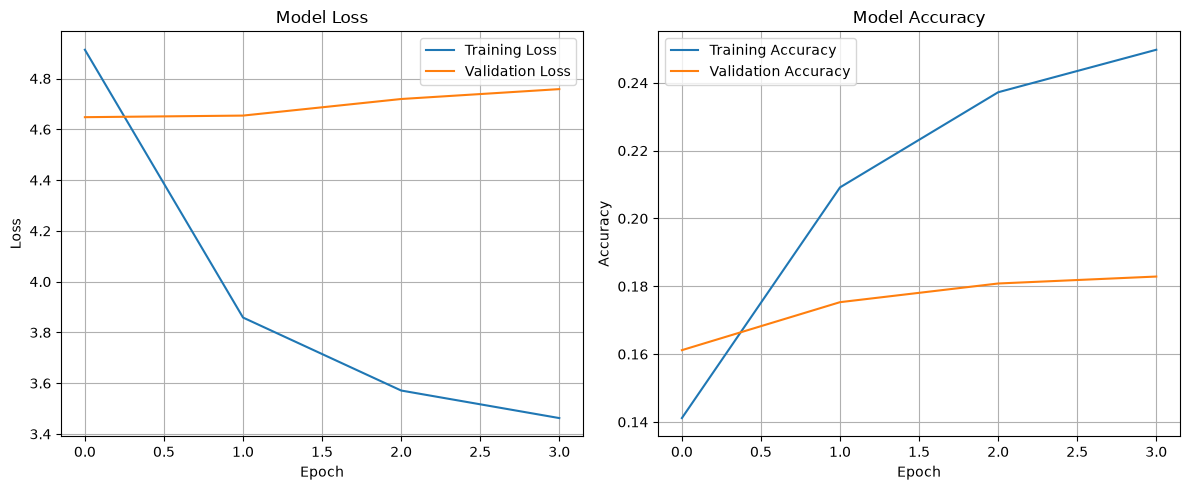

Best epoch: 1
loss: 4.9134
accuracy: 0.1411
val_loss: 4.6478
val_accuracy: 0.1612
Training time: 1165.20 seconds


In [14]:
# train
batch_size = 32
epochs = 30

start_time = time.perf_counter()

history_02 = model_clean_dropout03.fit(
    train_inputs_clean, train_targets_clean,
    validation_data=(val_inputs_clean, val_targets_clean),
    batch_size=batch_size,
    epochs=epochs,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=1),
        keras.callbacks.ModelCheckpoint('gutenberg_best_model_clean_dropout03.keras', save_best_only=True)
    ]
)

training_time = time.perf_counter() - start_time

# plot training results
plot_training_metrics(history_02)

# save the model
model_clean_dropout03.save('gutenberg_model_clean_dropout03.keras')

# get the best epoch
best_epoch = int(np.argmin(history_02.history['val_loss']))
print(f"Best epoch: {best_epoch + 1}")

# print results
for key in ['loss', 'accuracy', 'val_loss', 'val_accuracy']:
    print(f"{key}: {history_02.history[key][best_epoch]:.4f}")

print(f"Training time: {training_time:.2f} seconds")

### Model 3
Next, we try a smaller model. Let's change dropout back to 0.1. The model is saved as `model_clean_small`.

In [15]:
# define model parameters
embed_dim = 32
num_heads = 2
ff_dim = 64
num_layers = 1

# create the model
inputs_clean_layer = keras.Input(shape=(seq_length,))
embedding_layer = keras.layers.Embedding(sp_clean.get_piece_size(), embed_dim)(inputs_clean_layer)

# add positional encoding
pos_encoding = get_positional_encoding(seq_length, embed_dim)
x = embedding_layer + pos_encoding

# transformer blocks
for _ in range(num_layers):
    attention_output = keras.layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=embed_dim // num_heads,
        dropout=0.1
    )(x, x, use_causal_mask=True)
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + attention_output)

    ffn = keras.Sequential([
        keras.layers.Dense(ff_dim, activation="relu"),
        keras.layers.Dense(embed_dim),
        keras.layers.Dropout(0.1)
    ])
    ffn_output = ffn(x)
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + ffn_output)

# final output layer
outputs_clean = keras.layers.Dense(sp_clean.get_piece_size())(x)

model_clean_small = keras.Model(inputs=inputs_clean_layer, outputs=outputs_clean)

model_clean_small.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

model_clean_small.summary()

Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_6       │ (None, 64)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, 64, 32)    │     64,000 │ input_layer_6[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_10 (Add)        │ (None, 64, 32)    │          0 │ embedding_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 32)    │      4,224 │ add_10[0][0],     │
│ (MultiHeadAttentio… │                   │            │ add_10[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_11 (Add)        │ (None, 64, 32)    │          0 │ add_10[0][0],     │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 32)    │         64 │ add_11[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_4        │ (None, 64, 32)    │      4,192 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_12 (Add)        │ (None, 64, 32)    │          0 │ layer_normalizat… │
│                     │                   │            │ sequential_4[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 32)    │         64 │ add_12[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_12 (Dense)    │ (None, 64, 2000)  │     66,000 │ layer_normalizat… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 138,544 (541.19 KB)

 Trainable params: 138,544 (541.19 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 214s 56ms/step - accuracy: 0.1286 - loss: 5.1321 - val_accuracy: 0.1461 - val_loss: 4.8208 - learning_rate: 3.0000e-04
Epoch 2/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 216s 58ms/step - accuracy: 0.1819 - loss: 4.2217 - val_accuracy: 0.1554 - val_loss: 4.7414 - learning_rate: 3.0000e-04
Epoch 3/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 222s 60ms/step - accuracy: 0.1925 - loss: 4.0366 - val_accuracy: 0.1601 - val_loss: 4.7579 - learning_rate: 3.0000e-04
Epoch 4/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 212s 57ms/step - accuracy: 0.1996 - loss: 3.9518 - val_accuracy: 0.1616 - val_loss: 4.7703 - learning_rate: 1.5000e-04
Epoch 5/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 210s 57ms/step - accuracy: 0.2029 - loss: 3.9167 - val_accuracy: 0.1625 - val_loss: 4.7753 - learning_rate: 7.5000e-05
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 2.


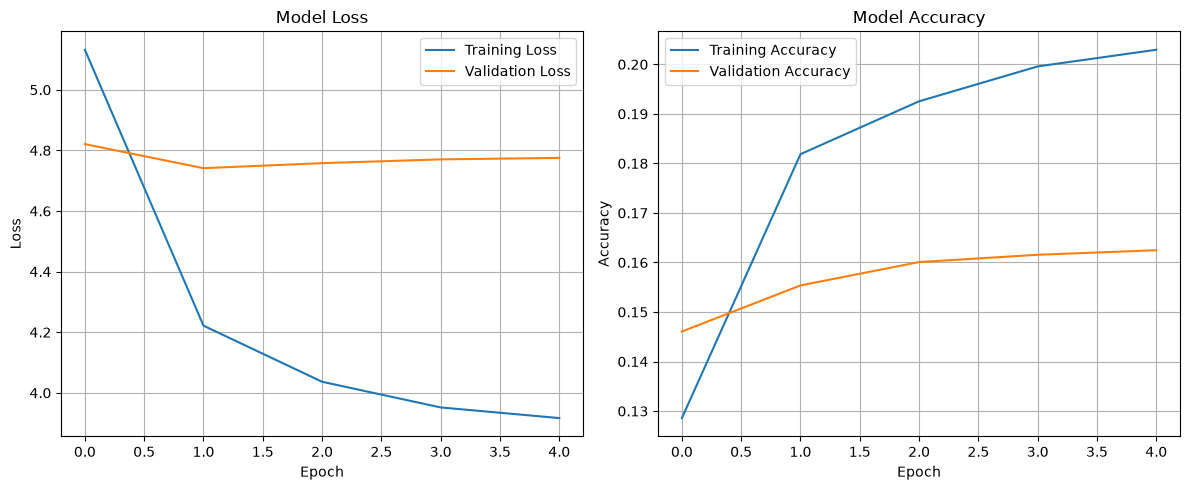

Best epoch: 2
loss: 4.2217
accuracy: 0.1819
val_loss: 4.7414
val_accuracy: 0.1554
Training time: 1073.68 seconds


In [16]:
# train
batch_size = 32
epochs = 30

start_time = time.perf_counter()

history_03 = model_clean_small.fit(
    train_inputs_clean, train_targets_clean,
    validation_data=(val_inputs_clean, val_targets_clean),
    batch_size=batch_size,
    epochs=epochs,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=1),
        keras.callbacks.ModelCheckpoint('gutenberg_best_model_clean_small.keras', save_best_only=True)
    ]
)

training_time = time.perf_counter() - start_time

# plot training results
plot_training_metrics(history_03)

# save the model
model_clean_small.save('gutenberg_model_clean_small.keras')

# get the best epoch
best_epoch = int(np.argmin(history_03.history['val_loss']))
print(f"Best epoch: {best_epoch + 1}")

# print results
for key in ['loss', 'accuracy', 'val_loss', 'val_accuracy']:
    print(f"{key}: {history_03.history[key][best_epoch]:.4f}")

print(f"Training time: {training_time:.2f} seconds")

### Model 4
Next, we try a model with a smaller vocabulary (1000). New tokenizer is created. This model is saved as `model_clean_v1000`

In [17]:
# tokenizer with vocab size 1000, trained on the clean text
temp_file_clean = 'gutenberg_temp_clean.txt'
with open(temp_file_clean, 'w', encoding='utf-8') as f:
    f.write(clean_text)

vocab_size_v1000 = 1000
model_prefix_v1000 = 'gutenberg_sp_v1000'

spm.SentencePieceTrainer.train(
    input=temp_file_clean,
    model_prefix=model_prefix_v1000,
    vocab_size=vocab_size_v1000,
    character_coverage=1.0,
    model_type='bpe',
    user_defined_symbols=['<PAD>', '<UNK>']
)

sp_v1000 = spm.SentencePieceProcessor()
sp_v1000.load(f"{model_prefix_v1000}.model")

tokens = sp_v1000.encode_as_pieces("It was from the Carlton Club")
print(f"Tokenized example: {tokens}")
print(f"Vocabulary size: {sp_v1000.get_piece_size()}")

Tokenized example: ['▁It', '▁was', '▁from', '▁the', '▁C', 'ar', 'l', 't', 'on', '▁C', 'l', 'ub']
Vocabulary size: 1000


Then we prepare the training data.

In [18]:
# prepare training data with the 1000-token vocabulary
pieces_v1000 = sp_v1000.encode_as_ids(clean_text)
print(f"Total tokens: {len(pieces_v1000)}")

sequences_v1000 = []
for i in range(0, len(pieces_v1000) - seq_length):
    sequences_v1000.append(pieces_v1000[i:i + seq_length + 1])

sequences_v1000 = np.array(sequences_v1000)
inputs_v1000 = sequences_v1000[:, :-1]
targets_v1000 = sequences_v1000[:, 1:]

print(f"Number of sequences: {len(sequences_v1000)}")
print(f"Input shape: {inputs_v1000.shape}")

# 90 % train / 10 % validation
split_v1000 = int(0.9 * len(sequences_v1000))
train_inputs_v1000 = inputs_v1000[:split_v1000]
train_targets_v1000 = targets_v1000[:split_v1000]
val_inputs_v1000 = inputs_v1000[split_v1000 + seq_length:]
val_targets_v1000 = targets_v1000[split_v1000 + seq_length:]

Total tokens: 153183
Number of sequences: 153119
Input shape: (153119, 64)


Next, we create the model.

In [19]:
# define model parameters (same as model 1)
embed_dim = 64
num_heads = 2
ff_dim = 128
num_layers = 2

# create the model
inputs_v1000_layer = keras.Input(shape=(seq_length,))
embedding_layer = keras.layers.Embedding(sp_v1000.get_piece_size(), embed_dim)(inputs_v1000_layer)

# add positional encoding
pos_encoding = get_positional_encoding(seq_length, embed_dim)
x = embedding_layer + pos_encoding

# transformer blocks
for _ in range(num_layers):
    attention_output = keras.layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=embed_dim // num_heads,
        dropout=0.1
    )(x, x, use_causal_mask=True)
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + attention_output)

    ffn = keras.Sequential([
        keras.layers.Dense(ff_dim, activation="relu"),
        keras.layers.Dense(embed_dim),
        keras.layers.Dropout(0.1)
    ])
    ffn_output = ffn(x)
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + ffn_output)

# final output layer
outputs_v1000 = keras.layers.Dense(sp_v1000.get_piece_size())(x)

model_clean_v1000 = keras.Model(inputs=inputs_v1000_layer, outputs=outputs_v1000)

model_clean_v1000.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

model_clean_v1000.summary()

Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_8       │ (None, 64)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_3         │ (None, 64, 64)    │     64,000 │ input_layer_8[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_13 (Add)        │ (None, 64, 64)    │          0 │ embedding_3[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 64)    │     16,640 │ add_13[0][0],     │
│ (MultiHeadAttentio… │                   │            │ add_13[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_14 (Add)        │ (None, 64, 64)    │          0 │ add_13[0][0],     │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_14[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_5        │ (None, 64, 64)    │     16,576 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_15 (Add)        │ (None, 64, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ sequential_5[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_15[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 64)    │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_16 (Add)        │ (None, 64, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_16[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_6        │ (None, 64, 64)    │     16,576 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_17 (Add)        │ (None, 64, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ sequential_6[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_17[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_17 (Dense)    │ (None, 64, 1000)  │     65,000 │ layer_normalizat… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 195,944 (765.41 KB)

 Trainable params: 195,944 (765.41 KB)

 Non-trainable params: 0 (0.00 B)

Let's train it.

In [20]:
batch_size = 32
epochs = 30

start_time = time.perf_counter()

history_04 = model_clean_v1000.fit(
    train_inputs_v1000, train_targets_v1000,
    validation_data=(val_inputs_v1000, val_targets_v1000),
    batch_size=batch_size,
    epochs=epochs,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=1),
        keras.callbacks.ModelCheckpoint('gutenberg_best_model_clean_v1000.keras', save_best_only=True)
    ]
)

training_time = time.perf_counter() - start_time

Epoch 1/30
4307/4307 ━━━━━━━━━━━━━━━━━━━━ 252s 56ms/step - accuracy: 0.1535 - loss: 4.4074 - val_accuracy: 0.1790 - val_loss: 4.1576 - learning_rate: 3.0000e-04
Epoch 2/30
4307/4307 ━━━━━━━━━━━━━━━━━━━━ 263s 61ms/step - accuracy: 0.2283 - loss: 3.6203 - val_accuracy: 0.2110 - val_loss: 4.0926 - learning_rate: 3.0000e-04
Epoch 3/30
4307/4307 ━━━━━━━━━━━━━━━━━━━━ 249s 58ms/step - accuracy: 0.2633 - loss: 3.3788 - val_accuracy: 0.2212 - val_loss: 4.1289 - learning_rate: 3.0000e-04
Epoch 4/30
4307/4307 ━━━━━━━━━━━━━━━━━━━━ 251s 58ms/step - accuracy: 0.2826 - loss: 3.2511 - val_accuracy: 0.2233 - val_loss: 4.1459 - learning_rate: 1.5000e-04
Epoch 5/30
4307/4307 ━━━━━━━━━━━━━━━━━━━━ 257s 60ms/step - accuracy: 0.2907 - loss: 3.1973 - val_accuracy: 0.2255 - val_loss: 4.1573 - learning_rate: 7.5000e-05
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 2.


The training metrics:

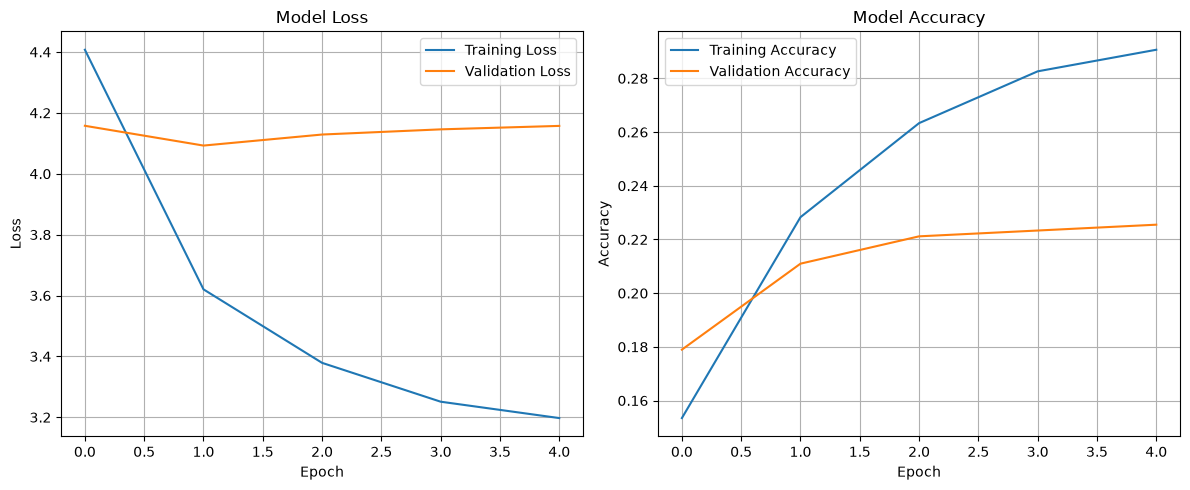

Best epoch: 2
loss: 3.6203
accuracy: 0.2283
val_loss: 4.0926
val_accuracy: 0.2110
Training time: 1271.19 seconds


In [21]:
plot_training_metrics(history_04)

model_clean_v1000.save('gutenberg_model_clean_v1000.keras')

best_epoch = int(np.argmin(history_04.history['val_loss']))
print(f"Best epoch: {best_epoch + 1}")
for key in ['loss', 'accuracy', 'val_loss', 'val_accuracy']:
    print(f"{key}: {history_04.history[key][best_epoch]:.4f}")

print(f"Training time: {training_time:.2f} seconds")

The model achieved a validation loss of 4.0926, which is the lowest of all the fife models (1-5). However, this model has a smaller vocabulary of 1,000 tokens compared to the other models (2,000 tokens). This means that model 4 is not straight compatible with other models.  

Validation loss measures the prediction error per one token. Different vocabulary sizes might result in different tokenizations of the same text, and the average length per token might be different. So, a lower validation loss might not necessarily mean that model 4 is better than the other models.

### Model 5

In this final model, we increase the model parameters. Other than that, the model is same as model 1. 

This model uses `attention-head 4`, instead of 2 as in other models. `embed_dim` and `ff_dim` also use bigger parameters. The training also goes trough 3 number of `layers`. This model is saved as `model_clean_big`.

In [22]:
# define model parameters
embed_dim = 128
num_heads = 4
ff_dim = 256
num_layers = 3

# create the model
inputs_clean_layer = keras.Input(shape=(seq_length,))
embedding_layer = keras.layers.Embedding(sp_clean.get_piece_size(), embed_dim)(inputs_clean_layer)

# add positional encoding
pos_encoding = get_positional_encoding(seq_length, embed_dim)
x = embedding_layer + pos_encoding

# transformer blocks
for _ in range(num_layers):
    attention_output = keras.layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=embed_dim // num_heads,
        dropout=0.1
    )(x, x, use_causal_mask=True)
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + attention_output)

    ffn = keras.Sequential([
        keras.layers.Dense(ff_dim, activation="relu"),
        keras.layers.Dense(embed_dim),
        keras.layers.Dropout(0.1)
    ])
    ffn_output = ffn(x)
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + ffn_output)

# final output layer
outputs_clean = keras.layers.Dense(sp_clean.get_piece_size())(x)

model_clean_big = keras.Model(inputs=inputs_clean_layer, outputs=outputs_clean)

model_clean_big.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

model_clean_big.summary()

Model: "functional_14"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_11      │ (None, 64)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_4         │ (None, 64, 128)   │    256,000 │ input_layer_11[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_18 (Add)        │ (None, 64, 128)   │          0 │ embedding_4[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 128)   │     66,048 │ add_18[0][0],     │
│ (MultiHeadAttentio… │                   │            │ add_18[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_19 (Add)        │ (None, 64, 128)   │          0 │ add_18[0][0],     │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 128)   │        256 │ add_19[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_7        │ (None, 64, 128)   │     65,920 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_20 (Add)        │ (None, 64, 128)   │          0 │ layer_normalizat… │
│                     │                   │            │ sequential_7[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 128)   │        256 │ add_20[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 128)   │     66,048 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_21 (Add)        │ (None, 64, 128)   │          0 │ layer_normalizat… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 128)   │        256 │ add_21[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_8        │ (None, 64, 128)   │     65,920 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_22 (Add)        │ (None, 64, 128)   │          0 │ layer_normalizat… │
│                     │                   │            │ sequential_8[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 128)   │        256 │ add_22[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 128)   │     66,048 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_23 (Add)        │ (None, 64, 128)   │          0 │ layer_normalizat… │
│                     │                   │            │ multi_head_atten

 Total params: 911,440 (3.48 MB)

 Trainable params: 911,440 (3.48 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 590s 155ms/step - accuracy: 0.1812 - loss: 4.4297 - val_accuracy: 0.1856 - val_loss: 4.5365 - learning_rate: 3.0000e-04
Epoch 2/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 591s 159ms/step - accuracy: 0.3243 - loss: 3.0300 - val_accuracy: 0.1837 - val_loss: 5.1174 - learning_rate: 3.0000e-04
Epoch 3/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 571s 154ms/step - accuracy: 0.4379 - loss: 2.3380 - val_accuracy: 0.1767 - val_loss: 5.5653 - learning_rate: 1.5000e-04
Epoch 4/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 575s 155ms/step - accuracy: 0.4955 - loss: 2.0395 - val_accuracy: 0.1743 - val_loss: 5.8242 - learning_rate: 7.5000e-05
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 1.


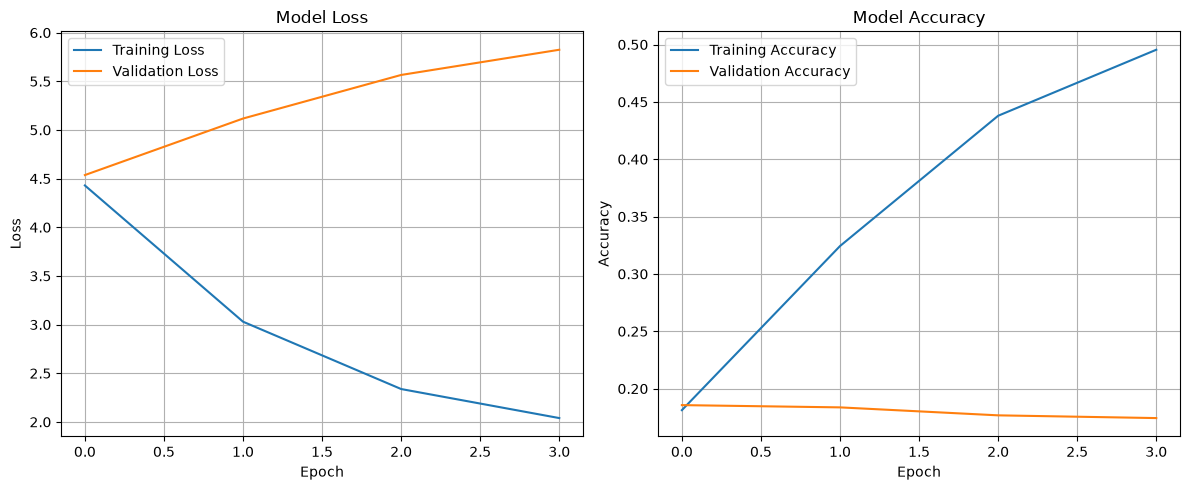

Best epoch: 1
loss: 4.4297
accuracy: 0.1812
val_loss: 4.5365
val_accuracy: 0.1856
Training time: 2327.16 seconds


In [23]:
# train
batch_size = 32
epochs = 30

start_time = time.perf_counter()

history_05 = model_clean_big.fit(
    train_inputs_clean, train_targets_clean,
    validation_data=(val_inputs_clean, val_targets_clean),
    batch_size=batch_size,
    epochs=epochs,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=1),
        keras.callbacks.ModelCheckpoint('gutenberg_best_model_clean_big.keras', save_best_only=True)
    ]
)

training_time = time.perf_counter() - start_time

# plot training results
plot_training_metrics(history_05)

# save the model
model_clean_big.save('gutenberg_model_clean_big.keras')

# get the best epoch
best_epoch = int(np.argmin(history_05.history['val_loss']))
print(f"Best epoch: {best_epoch + 1}")

# print results
for key in ['loss', 'accuracy', 'val_loss', 'val_accuracy']:
    print(f"{key}: {history_05.history[key][best_epoch]:.4f}")

print(f"Training time: {training_time:.2f} seconds")

Regardleds of using bigger parameters in this model, we didn't recive any better results. One notable difference compared to previous models is the used time in training, which doubles in size.

<h2>5. Evaluation</h2>

### Model comparison

Below is a summary of all the trained models. The values are taken from the best epoch. Note that model 4 uses a different vocabulary (1000 tokens), so its `val_loss` is not directly comparable to the other models, which all use a vocabulary of 2000 tokens.

| Model | Vocabulary size | Parameters | Best epoch | Val loss | Val accuracy | Training time (s) |
|---|---|---|---|---|---|---|
| 1 (clean) | 2000 | 324,944 | 1 | 4.631 | 0.163 | 1175 |
| 2 (dropout 0.3) | 2000 | 324,944 | 1 | 4.648 | 0.161 | 1165 |
| 3 (small) | 2000 | 138,544 | 2 | 4.741 | 0.155 | 1074 |
| 4 (vocabulary 1000) | 1000 | 195,944 | 2 | 4.093 | 0.211 | 1271 |
| 5 (big) | 2000 | 911,440 | 1 | 4.537 | 0.186 | 2327 |

**Findings:**
- The best epoch for each model is 1 or 2. After that, the validation loss starts to rise.
- The models overfit quickly, which might be caused by the small dataset. 
- When comparing models 1, 2, 3, and 5, which use the same tokenizer, model 5 has the lowest validation loss (4.537). However, its difference to model 1 (4.631) is small.
- Model 5 took almost twice as long to train as model 1.
- Model 4 has the lowest validation loss (4.093) and the highest validation accuracy (0.211), but it has smaller vocabulary and it is not directly comparable to other models.

#### Text generation

Let's generate text with the models above and compare the results. First, we use a temperature of 0.8. We use the first two prompts that have been defined before: "It was from the Carlton Club" and "Have you ever heard of Baron Gruner?"

In [26]:
models_to_compare = {
    "Model 1 (clean)": (model_clean, sp_clean),
    "Model 2 (clean, dropout 0.3)": (model_clean_dropout03, sp_clean),
    "Model 3 (small)": (model_clean_small, sp_clean),
    "Model 4 (vocabulary 1000)": (model_clean_v1000, sp_v1000),
    "Model 5 (big)": (model_clean_big, sp_clean),
}

for name, (m, tokenizer) in models_to_compare.items():
    np.random.seed(54)   # same seed for every model
    print(f"\n{name}")
    for prompt in prompts[:2]:
        print(f"\nPrompt: {prompt}")
        print(generate_text(m, tokenizer, prompt, num_tokens=60, temperature=0.8))


Model 1 (clean)

Prompt: It was from the Carlton Club
It was from the Carlton Clubmace as he cae. But the matter is authorfices. Have you have a rate asion of those very hy of all-hounded and that I was a thirty. There had broken be able to make him. But the same extra

Prompt: Have you ever heard of Baron Gruner?
Have you ever heard of Baron Gruner? What could that I was more serious to the believed. It was some recommy. I had been sble and fin of Mr. Naturely, there was a very by the message of which was not get further of the terror of those arel. "

Model 2 (clean, dropout 0.3)

Prompt: It was from the Carlton Club
It was from the Carlton Clubeuring from a step fellow, for a browning public suddenly. "That is, my way and I am sure that I don'll't look into the way upon the last time of the but none in an Gables, and secrelined commonorsle. There was

Prompt: Have you ever heard of Baron Gruner?
Have you ever heard of Baron Gruner? What has to you a dear well to the subject. It was

All of the models generate messy text containing words that do not exist in English. Model 5 generated the most invented words. Model 2 generated the most readable text, since most of its words are real.  

#### Different temperatures

Model 5 had the lowest validation loss but it did not generate readable text. Therefore, model 2 is used for the next experiments with different temperature values: 0.2, 0.5, 1.0 and 1.2. Let's use three different prompts.

In [28]:
temperatures = [0.2, 0.5, 1.0, 1.2]

for temp in temperatures:
    np.random.seed(54)
    print(f"\nTemperature: {temp}")
    for prompt in prompts[:3]:
        print(f"\nPrompt: {prompt}")
        print(generate_text(model_clean_dropout03, sp_clean, prompt, num_tokens=60, temperature=temp))


Temperature: 0.2

Prompt: It was from the Carlton Club
It was from the Carlton Clubeade, and I was a very clear. "I am not a very clear. But I was a very remarkable. I was a very clear-cotten, and I was a man of the man, and I had been a little to beardrocker, and I

Prompt: Have you ever heard of Baron Gruner?
Have you ever heard of Baron Gruner? I have been a lattering a luneeper, and I was a very beautiful, and I was a man and a man. "I have a little of the man of the house, and I have been a very beautiful, and I have been a little of the matter.

Prompt: Then you will sympathize with the client
Then you will sympathize with the client, and I was a very beautiful, and the man. "I am not be a very clear. I was a little of the man of the lady, and I was a very beautiful, and I was a very remarkable. "I am not a very beautiful, and I have been a very

Temperature: 0.5

Prompt: It was from the Carlton Club
It was from the Carlton Clubhouse of the soul. Aron, and I could not take the s

### Model 2 structure

Model 2 is a small transformer with 2 blocks, embedding size 64, 2 attention heads, feed-forward size 128 (ff_dim) and dropout 0.3. It has 324,944 parameters and predicts the next token from a vocabulary of 2000.

### Results

The goal was to build a transformer text generator and understand how different model settings affect the quality of generated text. 

Five transformer models were trained using different model sizes, dropout and vocabulary sizes. However, none of the models generated meaningful text. All models started to overfit after the first or second epoch.  

Model 5 had the lowest validation loss among the models that use the same tokenizer, but it did not generate more readable text and it took almost twice as long to train as model 1. Model 2, which had a higher dropout, generated the most readable text. This shows that validation loss alone does not describe the quality of the generated text.  

Temperature had a clear effect on the text generated by model 2. With a temperature of 0.2 the text was repetitive. A temperature of 0.5 gave the most readable text, but also some invented new words. Temperatures 1.0 and 1.2 were more chaotic and random. In this experiment, a temperature 0.5 worked best with model 2.  

<h2>6. Deployment</h2>

This model works only as a prototype since it has been trained with a small dataset. It would need much more data. Or maybe a pre-trained model should be used for real world text generation.  

Training a transformer from scratch is slow and demanding because the model starts with random weights and has to learn the language only from the training data. To create a good text generator requires a large dataset, which increases the training time and requires a lot of computing power. Our small models took 18 to 39 minutes each to train, and still they overfitted after first or second epoch.